# 01 · Exploratory Data Analysis — UK card transactions

**Goal of the project:** spot fraudulent card payments for a UK bank, so they can be blocked or checked before money is lost.

**Goal of this notebook:** understand the data *before* modelling. What does fraud look like, and how rare is it?

> The data is **synthetic** (generated by `data/generate_uk_transactions.py`). Real bank data is confidential. Every column has a real-world meaning, unlike the famous Kaggle dataset where the features are hidden as V1…V28.

In [1]:
import sys
from pathlib import Path
sys.path.append(str(Path.cwd().parent))   # so we can import src/utils.py

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import warnings
warnings.filterwarnings("ignore")

from src.utils import *   # load_data, time_split, make_preprocessor, evaluate, ...

RANDOM_STATE = 42
plt.rcParams["figure.figsize"] = (8, 4.5)

In [2]:
df = load_data()
print(df.shape)
df.head()

(250000, 25)


,transaction_id,customer_id,timestamp,amount_gbp,merchant_category,channel,card_type,home_region,transaction_region,is_international,...,is_new_merchant,failed_pin_attempts,sca_authenticated,is_fraud,hour,is_night,is_weekend,log_amount,amount_to_avg_ratio,region_mismatch
0,T0000000,C03495,2026-09-01 00:07:20,75.22,online_retail,online,debit,North East,North East,0,...,0,0,0,0,0,1,0,4.333624,0.828140,0
1,T0000001,C03048,2026-09-01 00:07:30,153.32,cash_withdrawal,atm,debit,Scotland,South West,0,...,1,0,0,0,0,1,0,5.039028,4.162911,1
2,T0000002,C04319,2026-09-01 00:16:37,41.41,grocery,contactless,credit,East of England,Wales,0,...,1,0,0,1,0,1,0,3.747384,1.276510,1
3,T0000003,C00129,2026-09-01 00:17:25,39.46,cash_withdrawal,atm,debit,East Midlands,East Midlands,0,...,0,0,0,0,0,1,0,3.700314,1.754558,0
4,T0000004,C01120,2026-09-01 00:17:34,53.81,grocery,contactless,debit,Yorkshire and the Humber,Yorkshire and the Humber,0,...,0,0,0,0,0,1,0,4.003873,1.166739,0


## 1. What columns do we have?

| Column | Meaning |
|---|---|
| `amount_gbp` | Payment amount in pounds |
| `merchant_category` | Type of shop (grocery, online_retail, gambling…) |
| `channel` | How the card was used: chip & PIN, contactless (max £100 in the UK), online, mobile wallet, ATM |
| `is_international` | Payment made outside the UK |
| `distance_from_home_km` | How far from the customer's home region |
| `txn_count_last_1h / 24h` | **Velocity** — how many payments the card made recently |
| `is_new_merchant` | First time this customer has paid this shop |
| `sca_authenticated` | Passed Strong Customer Authentication / 3-D Secure (online only) |
| `failed_pin_attempts` | Wrong PINs before this payment |
| `is_fraud` | **Target**: 1 = fraud, 0 = genuine |

Columns like `hour`, `is_night`, `amount_to_avg_ratio`, `region_mismatch` were added in `src/utils.py → add_features()` (that's **feature engineering**).

In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 250000 entries, 0 to 249999
Data columns (total 25 columns):
 #   Column                  Non-Null Count   Dtype         
---  ------                  --------------   -----         
 0   transaction_id          250000 non-null  str           
 1   customer_id             250000 non-null  str           
 2   timestamp               250000 non-null  datetime64[us]
 3   amount_gbp              250000 non-null  float64       
 4   merchant_category       250000 non-null  str           
 5   channel                 250000 non-null  str           
 6   card_type               250000 non-null  str           
 7   home_region             250000 non-null  str           
 8   transaction_region      250000 non-null  str           
 9   is_international        250000 non-null  int64         
 10  distance_from_home_km   250000 non-null  float64       
 11  account_age_months      250000 non-null  int64         
 12  customer_avg_spend_gbp  250000 non-null  

In [4]:
df.describe().T.round(2)

,count,mean,min,25%,50%,75%,max,std
timestamp,250000,2026-09-16 02:44:59.359728,2026-09-01 00:07:20,2026-09-08 15:09:14.750000,2026-09-16 03:39:54,2026-09-23 14:40:26.250000,2026-09-30 23:58:32,NaN
amount_gbp,250000.0,52.284641,0.52,20.15,35.95,65.37,2590.38,59.606798
is_international,250000.0,0.04012,0.0,0.0,0.0,0.0,1.0,0.196241
distance_from_home_km,250000.0,239.756638,0.0,2.2,5.9,16.3,8999.7,1034.873735
account_age_months,250000.0,75.609456,1.0,40.0,66.0,100.0,382.0,47.93788
customer_avg_spend_gbp,250000.0,37.842288,4.01,26.54,34.83,45.74,248.42,16.002331
txn_count_last_1h,250000.0,0.403308,0.0,0.0,0.0,1.0,9.0,0.640266
txn_count_last_24h,250000.0,3.404852,0.0,2.0,3.0,5.0,18.0,1.856192
is_new_merchant,250000.0,0.220228,0.0,0.0,0.0,0.0,1.0,0.414401
failed_pin_attempts,250000.0,0.006384,0.0,0.0,0.0,0.0,3.0,0.081531


## 2. How rare is fraud? (the most important fact in the whole project)

In [5]:
counts = df["is_fraud"].value_counts()
print(counts)
print(f"\nFraud rate: {df['is_fraud'].mean():.3%}")
print(f"A model that ALWAYS says 'genuine' would be {1 - df['is_fraud'].mean():.2%} accurate - and catch zero fraud.")

is_fraud
0    249375
1       625
Name: count, dtype: int64

Fraud rate: 0.250%
A model that ALWAYS says 'genuine' would be 99.75% accurate - and catch zero fraud.


Only about **1 in 400** payments is fraud. This is called a **class imbalance**.

👉 This means **accuracy is a useless metric here**. We will judge models on **recall** (what % of fraud we catch), **precision** (when we flag something, how often is it really fraud) and **PR-AUC**.

## 3. Where does fraud happen?

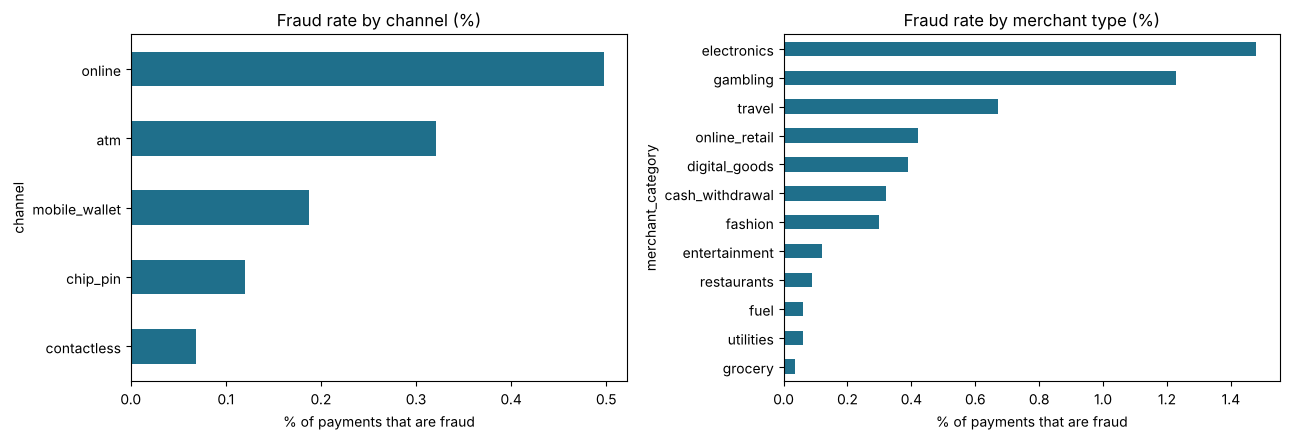

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
(df.groupby("channel")["is_fraud"].mean() * 100).sort_values().plot.barh(ax=axes[0], color="#1f6f8b")
axes[0].set_title("Fraud rate by channel (%)"); axes[0].set_xlabel("% of payments that are fraud")
(df.groupby("merchant_category")["is_fraud"].mean() * 100).sort_values().plot.barh(ax=axes[1], color="#1f6f8b")
axes[1].set_title("Fraud rate by merchant type (%)"); axes[1].set_xlabel("% of payments that are fraud")
plt.tight_layout()
plt.savefig("../images/fraud_rate_by_channel_merchant.png", dpi=120, bbox_inches="tight")
plt.show()

**Insight:** online ("card not present") payments, electronics, gambling and travel carry far more fraud. This matches the real UK picture, where remote purchase fraud is the biggest category of card fraud cases.

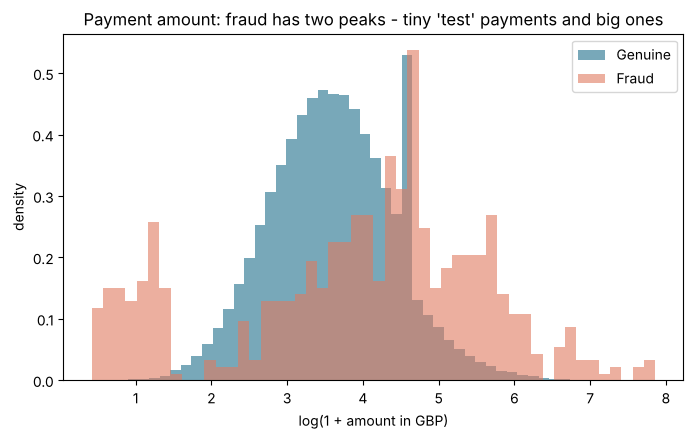

In [7]:
fig, ax = plt.subplots()
for label, name, colour in [(0, "Genuine", "#1f6f8b"), (1, "Fraud", "#e07a5f")]:
    ax.hist(df.loc[df["is_fraud"] == label, "log_amount"], bins=50, density=True, alpha=0.6, label=name, color=colour)
ax.set_xlabel("log(1 + amount in GBP)"); ax.set_ylabel("density"); ax.legend()
ax.set_title("Payment amount: fraud has two peaks - tiny 'test' payments and big ones")
plt.savefig("../images/amount_distribution.png", dpi=120, bbox_inches="tight")
plt.show()

Notice the **two fraud peaks**: fraudsters often make a tiny "test" payment (£1–£3) to check a stolen card works, then go for big purchases. We used `log_amount` because raw amounts are very skewed (a few huge values).

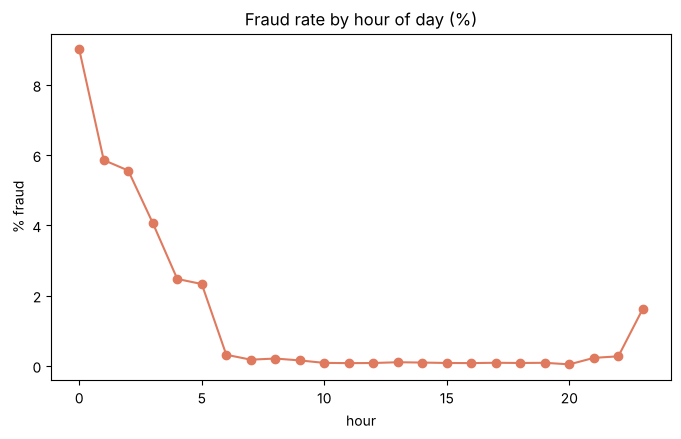

In [8]:
hourly = df.groupby("hour")["is_fraud"].mean() * 100
hourly.plot(marker="o", color="#e07a5f")
plt.title("Fraud rate by hour of day (%)"); plt.xlabel("hour"); plt.ylabel("% fraud")
plt.savefig("../images/fraud_by_hour.png", dpi=120, bbox_inches="tight")
plt.show()

## 4. Behaviour signals

In [9]:
signals = ["is_international", "is_new_merchant", "region_mismatch", "is_night", "sca_authenticated"]
summary = df.groupby("is_fraud")[signals + ["txn_count_last_1h", "amount_to_avg_ratio", "failed_pin_attempts"]].mean().T
summary.columns = ["Genuine (avg)", "Fraud (avg)"]
summary.round(3)

,Genuine (avg),Fraud (avg)
is_international,0.040,0.176
is_new_merchant,0.219,0.686
region_mismatch,0.197,0.510
is_night,0.032,0.517
sca_authenticated,0.229,0.205
txn_count_last_1h,0.400,1.754
amount_to_avg_ratio,1.446,4.271
failed_pin_attempts,0.006,0.096


**Reading this table:** e.g. if `is_new_merchant` is 0.22 for genuine and ~0.7 for fraud, that means 22% of genuine payments go to a new shop, but ~70% of fraud does. Big differences = useful features. Fraud also has more payments in the last hour (velocity).

`sca_authenticated` looks almost the same in both groups — but that's misleading, because SCA only applies to **online** payments. Let's look at online payments only:

In [10]:
online = df[df["channel"] == "online"]
online.groupby("is_fraud")["sca_authenticated"].mean().rename({0: "Genuine", 1: "Fraud"}).round(3)

is_fraud
Genuine    0.698
Fraud      0.270
Name: sca_authenticated, dtype: float64

Among online payments, genuine ones are mostly authenticated with SCA / 3-D Secure, while most fraud is not. Lesson: **always check a feature within the right subgroup** before deciding it is useless.

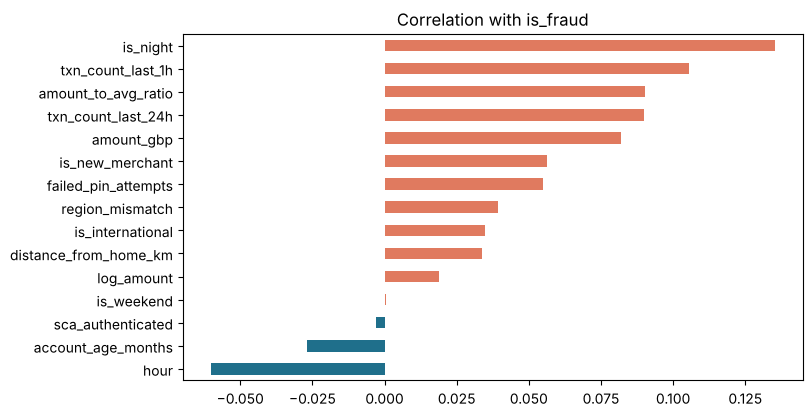

In [11]:
# correlation of each numeric feature with the target
corr = df[NUMERIC_FEATURES + ["is_fraud"]].corr()["is_fraud"].drop("is_fraud").sort_values()
corr.plot.barh(color=["#e07a5f" if v > 0 else "#1f6f8b" for v in corr])
plt.title("Correlation with is_fraud"); plt.show()

## 5. Takeaways for modelling

1. **Heavy imbalance (0.25% fraud)** → ignore accuracy; use recall, precision, PR-AUC and a **£ cost**; handle imbalance with class weights or oversampling (SMOTE).
2. **Split by time**, not randomly: train on 1–21 Sep, tune on 22–25 Sep, test on 26–30 Sep — like a real bank predicting next week's fraud.
3. Useful signals: channel, merchant type, velocity, new merchant, international, night-time, missing SCA, amount vs the customer's normal spend.
4. Categorical columns need **one-hot encoding**; numeric columns need **scaling** for logistic regression, k-means and neural networks.